# 02 · Statistics: does late delivery cause bad reviews, and how would we test a free-shipping threshold?

**Part A** uses the **real** Olist data to test whether late orders get worse reviews, how large the effect is, and whether it survives controls for product category and customer state.

**Part B** is a **SIMULATED A/B test**. Olist never ran this experiment and the dataset has no sessions or experiment logs. Every visitor-level outcome in Part B is generated by a random-number generator. Only the inputs (baseline rate, traffic, order values, freight and review scores) are **calibrated to the real data**. Part B shows how the experiment would be designed and analysed, not what the result was.

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.miscmodels.ordinal_model import OrderedModel

from olist.config import METRICS_DIR, RANDOM_SEED
from olist.plotting import INK_SECONDARY, SERIES, save, use_style
from olist.stats.abtest import (
    beta_binomial,
    peeking_false_positive_rate,
    power_at_n,
    sample_size_per_arm,
    simulate_ab,
    srm_check,
    two_proportion_test,
)
from olist.stats.effect_sizes import compare_groups
from olist.warehouse import connect, order_facts

warnings.filterwarnings("ignore", category=RuntimeWarning)
use_style()
con = connect()
orders = order_facts(con)
results = {}
print(f"{len(orders):,} valid orders")

98,199 valid orders


## Part A · Late delivery vs review score (real data)

**Population:** delivered orders that have a review and both a delivery date and an estimated date. **Late** means delivered after the estimated date (comparing calendar days).

**Hypotheses:** H0 says late and on-time orders have the same review-score distribution. H1 says they differ (two-sided, α = 0.05).

**Why several tests?**
- Review score is ordinal (1–5) and heavily skewed, so the **Mann-Whitney U** test is the primary test, with **Cliff's delta** as its effect size.
- **Welch's t-test** and **Cohen's d** are reported because stakeholders think in means. With n in the thousands the CLT makes the mean comparison valid, and Welch does not assume equal variances.
- **Bootstrap 95% CIs** show how precise each effect size is, without assuming normality.

In [2]:
d = orders[(orders.order_status == "delivered") & orders.delay_days.notna() & orders.review_score.notna()].copy()
late = d.loc[d.is_late == 1, "review_score"].to_numpy()
ontime = d.loc[d.is_late == 0, "review_score"].to_numpy()
cmp = compare_groups(late, ontime, n_boot=1000, seed=RANDOM_SEED)
summary = pd.DataFrame(
    {
        "value": [cmp.n_a, cmp.n_b, cmp.mean_a, cmp.mean_b, cmp.mean_diff, cmp.welch_t, cmp.welch_p, cmp.mannwhitney_p, cmp.cohens_d, cmp.cliffs_delta],
        "95% bootstrap CI": ["", "", "", "", f"[{cmp.mean_diff_ci[0]:.3f}, {cmp.mean_diff_ci[1]:.3f}]", "", "", "",
                             f"[{cmp.cohens_d_ci[0]:.3f}, {cmp.cohens_d_ci[1]:.3f}]", f"[{cmp.cliffs_delta_ci[0]:.3f}, {cmp.cliffs_delta_ci[1]:.3f}]"],
    },
    index=["n late", "n on time", "mean score late", "mean score on time", "difference (late - on time)", "Welch t", "Welch p", "Mann-Whitney p", "Cohen's d", "Cliff's delta"],
)
print(f"Cliff's delta magnitude: {cmp.cliffs_label}")
results["late_vs_ontime"] = {k: (list(v) if isinstance(v, tuple) else v) for k, v in cmp.__dict__.items()}
summary

Cliff's delta magnitude: large


,value,95% bootstrap CI
n late,6381.000000,
n on time,89443.000000,
mean score late,2.271823,
mean score on time,4.290589,
difference (late - on time),-2.018767,"[-2.061, -1.975]"
Welch t,-100.744397,
Welch p,0.000000,
Mann-Whitney p,0.000000,
Cohen's d,-1.709613,"[-1.749, -1.671]"
Cliff's delta,-0.637980,"[-0.650, -0.626]"


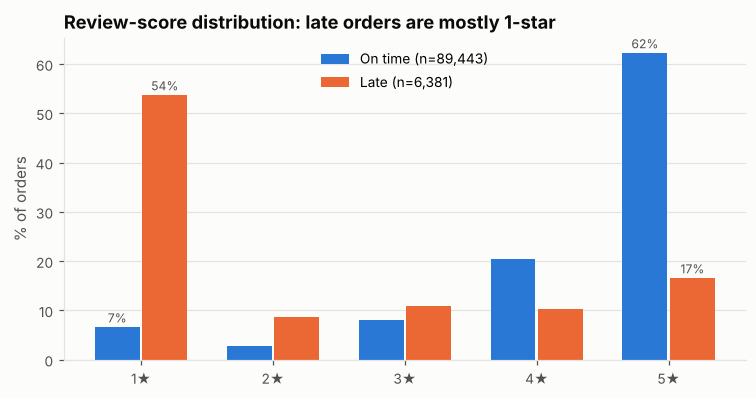

In [3]:
dist = (
    d.assign(group=np.where(d.is_late == 1, "Late", "On time"), score=d.review_score.round().astype(int))
    .groupby("group").score.value_counts(normalize=True).unstack(fill_value=0)
)
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(1, 6)
for i, g in enumerate(["On time", "Late"]):
    ax.bar(x + (i - 0.5) * 0.36, dist.loc[g] * 100, width=0.34, color=SERIES[i], label=f"{g} (n={(d.is_late == (g == 'Late')).sum():,})")
for i, g in enumerate(["On time", "Late"]):
    for s in (1, 5):
        ax.text(s + (i - 0.5) * 0.36, dist.loc[g, s] * 100 + 1, f"{dist.loc[g, s]:.0%}", ha="center", fontsize=8, color=INK_SECONDARY)
ax.set_xticks(x, [f"{s}★" for s in x])
ax.set_ylabel("% of orders")
ax.set_title("Review-score distribution: late orders are mostly 1-star")
ax.legend()
save(fig, "late_review_distribution")
plt.show()

**Reading the result.** **6,381** late orders average **2.27 stars**, against **4.29** for **89,443** on-time orders. The difference is **−2.02 stars**, with a 95% bootstrap CI of −2.06 to −1.98. **53.7%** of late orders get 1 star, compared with **6.6%** of on-time orders. Both tests reject H0 decisively (Welch t = −100.7; both p-values underflow to 0). The effect is **large** on either scale: Cohen's d = **−1.71** [−1.75, −1.67] and Cliff's delta = **−0.64** [−0.65, −0.63]. With samples this large, any difference would be "significant", so the effect size is what matters here, and it is large.

### Controlled check: ordinal logistic regression

Late orders are not random. They are concentrated in some states (north-east) and categories (bulky goods), which may have lower reviews for other reasons. A **proportional-odds (ordinal logit)** model of review score on `is_late` adds controls for the top 15 categories, the top 10 customer states, multi-item baskets, freight share and order value (log). If the late coefficient stays large with these controls, confounding by category or region does not explain the effect.

The model is fitted on a random sample of 40,000 orders to keep it quick. The coefficient is very stable, as the CI below shows.

In [4]:
top_cat = d.category.value_counts().head(15).index
top_state = d.customer_state.value_counts().head(10).index
m = d.sample(40_000, random_state=RANDOM_SEED) if len(d) > 40_000 else d.copy()
X = pd.DataFrame(
    {
        "is_late": m.is_late.astype(float),
        "multi_item": (m.n_items > 1).astype(float),
        "freight_share": (m.freight_value / m.order_value).fillna(0),
        "log_order_value": np.log1p(m.order_value),
    },
    index=m.index,
)
X = X.join(pd.get_dummies(m.category.where(m.category.isin(top_cat), "other"), prefix="cat", dtype=float).drop(columns="cat_other"))
X = X.join(pd.get_dummies(m.customer_state.where(m.customer_state.isin(top_state), "other"), prefix="st", dtype=float).drop(columns="st_other"))
y = pd.Series(pd.Categorical(m.review_score.round().astype(int), ordered=True), index=m.index)
ordinal = OrderedModel(y, X, distr="logit").fit(method="bfgs", maxiter=2000, disp=False)
coef = ordinal.params["is_late"]
ci = ordinal.conf_int().loc["is_late"]
results["ordinal_late_coef"] = float(coef)
results["ordinal_late_or"] = float(np.exp(coef))
results["ordinal_late_or_ci"] = [float(np.exp(ci[0])), float(np.exp(ci[1]))]
results["ordinal_n"] = int(len(m))
print(f"is_late coefficient {coef:.3f}  ->  odds ratio {np.exp(coef):.3f}  (95% CI {np.exp(ci[0]):.3f}-{np.exp(ci[1]):.3f}), p = {ordinal.pvalues['is_late']:.2e}")
print(f"Odds of a HIGHER review when late are {1 / np.exp(coef):.1f}x lower than when on time, holding category, state, basket and value fixed.")
ordinal.summary().tables[1].data[:6]

is_late coefficient -2.686  ->  odds ratio 0.068  (95% CI 0.063-0.074), p = 0.00e+00
Odds of a HIGHER review when late are 14.7x lower than when on time, holding category, state, basket and value fixed.


[['', 'coef', 'std err', 'z', 'P>|z|', '[0.025', '0.975]'],
 ['is_late',
  '   -2.6865',
  '    0.041',
  '  -65.818',
  ' 0.000',
  '   -2.766',
  '   -2.606'],
 ['multi_item',
  '   -0.7086',
  '    0.036',
  '  -19.703',
  ' 0.000',
  '   -0.779',
  '   -0.638'],
 ['freight_share',
  '   -0.4110',
  '    0.125',
  '   -3.286',
  ' 0.001',
  '   -0.656',
  '   -0.166'],
 ['log_order_value',
  '   -0.0786',
  '    0.020',
  '   -4.003',
  ' 0.000',
  '   -0.117',
  '   -0.040'],
 ['cat_auto',
  '   -0.0339',
  '    0.054',
  '   -0.623',
  ' 0.534',
  '   -0.141',
  '    0.073']]

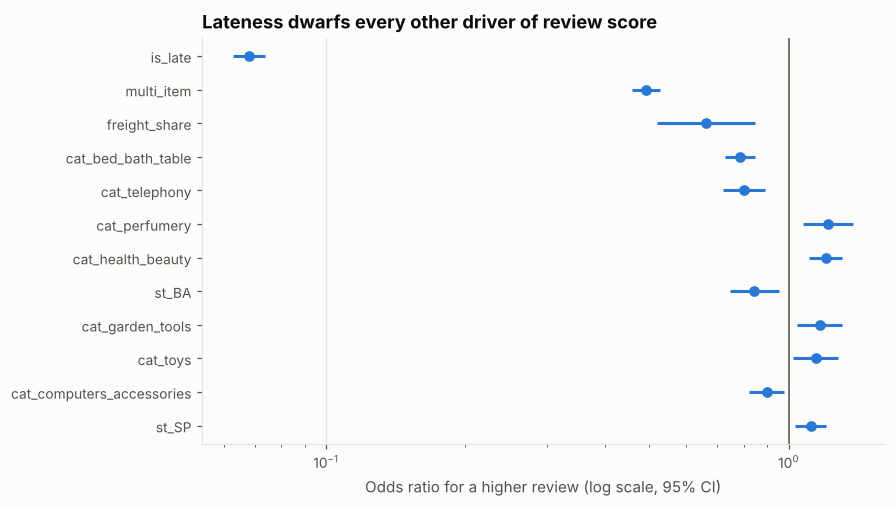

In [5]:
terms = ordinal.params.drop([c for c in ordinal.params.index if "/" in c])
ci_all = ordinal.conf_int().loc[terms.index]
show = terms.abs().sort_values(ascending=False).head(12).index[::-1]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.errorbar(np.exp(terms[show]), range(len(show)), xerr=[np.exp(terms[show]) - np.exp(ci_all.loc[show, 0]), np.exp(ci_all.loc[show, 1]) - np.exp(terms[show])],
            fmt="o", color=SERIES[0], ecolor=SERIES[0], markersize=6, capsize=0)
ax.axvline(1, color=INK_SECONDARY, linewidth=1)
ax.set_yticks(range(len(show)), show)
ax.set_xscale("log")
ax.set_xlabel("Odds ratio for a higher review (log scale, 95% CI)")
ax.set_title("Lateness dwarfs every other driver of review score")
ax.grid(axis="x", visible=True)
ax.grid(axis="y", visible=False)
save(fig, "ordinal_odds_ratios")
plt.show()

**So what (Part A).**
- Controlling for category, state, basket size, freight share and order value, a late order has an odds ratio of **0.068** (95% CI 0.063–0.074) for a higher review score. Being late cuts the odds of a better review **about 15-fold**. Every category and state effect lies between about 0.8 and 1.25, and the next-largest driver, a multi-item basket, has OR ≈ 0.49.
- Confounding by category or region therefore **does not explain** the late-delivery effect. Combined with the clear dose-response in EDA Q4 (later means worse), lateness is the main controllable driver of satisfaction.
- **Caveat:** this is observational data. Unmeasured factors such as seller quality or carrier choice could account for part of the effect. The way to confirm causality is an experiment on **promised dates**: pad the estimate on high-risk lanes and measure reviews.
- **Recommendation:** treat "late vs promise" as the top customer-experience KPI. Fixing lateness is worth more than any category or regional initiative.

## Part B · ⚠️ SIMULATED A/B test: a free-shipping threshold

> **Everything in Part B is simulated.** No such test was run at Olist. Inputs are calibrated to the real 2018 data (baseline rate, daily order volume, order value, freight and review distributions). Outcomes are random draws.

**Idea:** offer free shipping on orders whose items reach a threshold. Freight barely falls with basket size (EDA Q7), so customers currently have no reason to add a second item.

- **Unit of randomisation:** customer (sticky assignment), 50/50.
- **Primary metric:** multi-item order rate, i.e. the share of orders with 2 or more items.
- **Guardrails:** mean review score (multi-item orders review worse), average order value, and the freight subsidy per order (cost).
- **Decision rule (pre-registered):** ship if the primary metric is significant at α = 0.05 **and** no guardrail is significantly worse.

In [6]:
y2018 = orders[(orders.purchased_at >= "2018-01-01") & (orders.purchased_at < "2018-09-01")]
p0 = float((y2018.n_items > 1).mean())
daily_orders = len(y2018) / y2018.purchased_at.dt.normalize().nunique()
threshold = float(y2018.items_value.quantile(0.75))
print(f"Real baseline multi-item rate (Jan-Aug 2018): {p0:.2%}")
print(f"Real daily order volume (Jan-Aug 2018): {daily_orders:,.0f}")
print(f"Threshold used in the simulation = 75th percentile of item value: R$ {threshold:,.0f}")
results["ab_baseline_p0"] = p0
results["ab_daily_orders"] = daily_orders

Real baseline multi-item rate (Jan-Aug 2018): 9.90%
Real daily order volume (Jan-Aug 2018): 222
Threshold used in the simulation = 75th percentile of item value: R$ 150


### 1. Power analysis and sample size

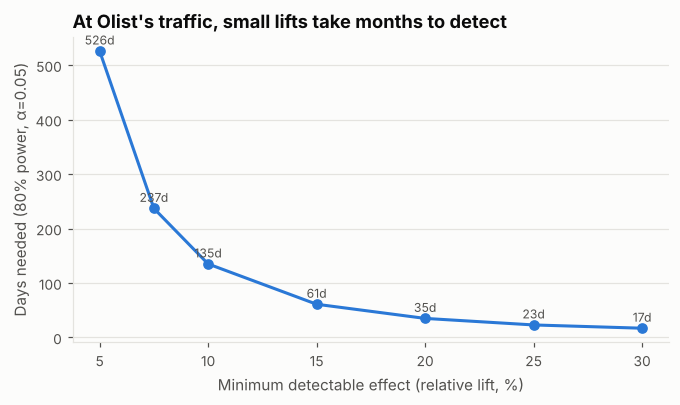

Chosen MDE = 15% relative (9.90% -> 11.39%): n = 6,763 per arm, 61 days -> run 9 full weeks (13,993 orders)
Power at the planned size: 81.3%


,relative MDE,n per arm,days at 100% traffic,weeks
0,0.050,58379,526,75.1
1,0.075,26225,237,33.9
2,0.100,14907,135,19.3
3,0.150,6763,61,8.7
4,0.200,3880,35,5.0
5,0.250,2531,23,3.3
6,0.300,1791,17,2.4


In [7]:
mdes = np.array([0.05, 0.075, 0.10, 0.15, 0.20, 0.25, 0.30])
plan = pd.DataFrame({"relative MDE": mdes, "n per arm": [sample_size_per_arm(p0, m) for m in mdes]})
plan["days at 100% traffic"] = np.ceil(2 * plan["n per arm"] / daily_orders).astype(int)
plan["weeks"] = (plan["days at 100% traffic"] / 7).round(1)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(plan["relative MDE"] * 100, plan["days at 100% traffic"], marker="o", color=SERIES[0])
for mde, days in zip(plan["relative MDE"], plan["days at 100% traffic"]):
    ax.text(mde * 100, days + 12, f"{days}d", ha="center", fontsize=8, color=INK_SECONDARY)
ax.set_xlabel("Minimum detectable effect (relative lift, %)")
ax.set_ylabel("Days needed (80% power, α=0.05)")
ax.set_title("At Olist's traffic, small lifts take months to detect")
save(fig, "ab_power_curve")
plt.show()
MDE = 0.15
n_arm = sample_size_per_arm(p0, MDE)
days = int(np.ceil(2 * n_arm / daily_orders))
weeks = int(np.ceil(days / 7))
n_total = int(weeks * 7 * daily_orders)
print(f"Chosen MDE = {MDE:.0%} relative ({p0:.2%} -> {p0 * (1 + MDE):.2%}): n = {n_arm:,} per arm, {days} days -> run {weeks} full weeks ({n_total:,} orders)")
print(f"Power at the planned size: {power_at_n(p0, MDE, n_total // 2):.1%}")
results.update({"ab_mde": MDE, "ab_n_per_arm": n_arm, "ab_weeks": weeks, "ab_n_total": n_total})
plan

### 2. Run the (simulated) experiment, then the SRM check *before* looking at results

Assumed true effect for the simulation: **+15% relative**, the planned MDE. Simulating exactly at the MDE means a real experiment would find it only about 80% of the time.

In [8]:
TRUE_LIFT = 0.15
sim = simulate_ab(p0, TRUE_LIFT, n_total, seed=RANDOM_SEED)
chi2, srm_p = srm_check(sim["n_a"], sim["n_b"])
print(f"Arm sizes A={sim['n_a']:,}  B={sim['n_b']:,}  ->  SRM chi2={chi2:.2f}, p={srm_p:.3f}  ({'OK' if srm_p > 0.001 else 'SRM! stop and debug assignment'})")
bad_chi2, bad_p = srm_check(int(n_total * 0.52), n_total - int(n_total * 0.52))
print(f"For contrast, a buggy 52/48 split of the same traffic: chi2={bad_chi2:.1f}, p={bad_p:.2e} -> would be flagged")
results.update({"ab_srm_p": srm_p, "ab_sim": sim})

Arm sizes A=7,016  B=6,977  ->  SRM chi2=0.11, p=0.742  (OK)
For contrast, a buggy 52/48 split of the same traffic: chi2=22.3, p=2.29e-06 -> would be flagged


### 3. Frequentist analysis

In [9]:
freq = two_proportion_test(sim["x_a"], sim["n_a"], sim["x_b"], sim["n_b"])
print(f"A: {freq.p_a:.2%}   B: {freq.p_b:.2%}   absolute diff {freq.abs_diff:+.2%} (95% CI {freq.abs_diff_ci[0]:+.2%} to {freq.abs_diff_ci[1]:+.2%})")
print(f"relative lift {freq.rel_lift:+.1%},  z = {freq.z:.2f},  p = {freq.p_value:.4f}")
results["ab_frequentist"] = {k: (list(v) if isinstance(v, tuple) else v) for k, v in freq.__dict__.items()}

A: 10.01%   B: 11.44%   absolute diff +1.43% (95% CI +0.41% to +2.46%)
relative lift +14.3%,  z = 2.74,  p = 0.0062


### 4. Bayesian analysis (Beta-Binomial, uniform prior)

The Bayesian view answers the question the business actually asks: *how likely is B better, and what do we lose if we ship B and it is not?* Expected loss is in percentage points of multi-item rate.

In [10]:
bayes = beta_binomial(sim["x_a"], sim["n_a"], sim["x_b"], sim["n_b"], seed=RANDOM_SEED)
print(f"P(B > A) = {bayes.prob_b_better:.1%}")
print(f"Expected loss if we ship B: {bayes.expected_loss_choose_b * 100:.3f} pp   (if we keep A: {bayes.expected_loss_choose_a * 100:.3f} pp)")
print(f"95% credible interval for relative lift: {bayes.lift_ci[0]:+.1%} to {bayes.lift_ci[1]:+.1%}")
results["ab_bayes"] = {k: (list(v) if isinstance(v, tuple) else v) for k, v in bayes.__dict__.items()}

P(B > A) = 99.7%
Expected loss if we ship B: 0.001 pp   (if we keep A: 1.432 pp)
95% credible interval for relative lift: +3.8% to +25.8%


### 5. Guardrails, resampled from real orders

Each simulated order is filled in by drawing a **real** 2018 order: a multi-item one if the simulated customer converted, a single-item one otherwise. Arm B gets free shipping when items reach the threshold, which Olist pays for. This shows the mechanical side effects. Multi-item orders review worse in the real data (EDA Q7), so a successful test can lower the review guardrail without any change in service quality.

In [11]:
rng = np.random.default_rng(RANDOM_SEED)
single = y2018[(y2018.n_items == 1) & y2018.review_score.notna()]
multi = y2018[(y2018.n_items > 1) & y2018.review_score.notna()]

def resample_arm(n, x, free_shipping):
    rows = pd.concat([multi.sample(x, replace=True, random_state=rng.integers(1e9)), single.sample(n - x, replace=True, random_state=rng.integers(1e9))])
    subsidy = np.where(free_shipping & (rows.items_value >= threshold), rows.freight_value, 0.0)
    return rows.assign(subsidy=subsidy)

arm_a = resample_arm(sim["n_a"], sim["x_a"], False)
arm_b = resample_arm(sim["n_b"], sim["x_b"], True)
from scipy import stats as st

guard = pd.DataFrame(
    {
        "A (control)": [arm_a.review_score.mean(), arm_a.order_value.mean(), arm_a.subsidy.mean()],
        "B (free shipping)": [arm_b.review_score.mean(), arm_b.order_value.mean(), arm_b.subsidy.mean()],
    },
    index=["mean review score", "average order value (R$)", "freight subsidy per order (R$)"],
)
guard["B - A"] = guard["B (free shipping)"] - guard["A (control)"]
guard["Welch p"] = [st.ttest_ind(arm_b.review_score, arm_a.review_score, equal_var=False).pvalue,
                    st.ttest_ind(arm_b.order_value, arm_a.order_value, equal_var=False).pvalue, np.nan]
results["ab_guardrails"] = guard.reset_index().to_dict(orient="records")
uplift_gmv = (freq.p_b - freq.p_a) * (multi.order_value.mean() - single.order_value.mean())
share_subsidised = (y2018.items_value >= threshold).mean()
print(f"Expected incremental GMV per order from the extra multi-item orders: R$ {uplift_gmv:.2f}")
print(f"Freight subsidy per order in B: R$ {arm_b.subsidy.mean():.2f}; {share_subsidised:.0%} of all orders already clear the threshold without changing behaviour")
results["ab_economics"] = {"incremental_gmv_per_order": float(uplift_gmv), "subsidy_per_order": float(arm_b.subsidy.mean()), "share_already_above_threshold": float(share_subsidised)}
guard

Expected incremental GMV per order from the extra multi-item orders: R$ 1.44
Freight subsidy per order in B: R$ 9.60; 26% of all orders already clear the threshold without changing behaviour


,A (control),B (free shipping),B - A,Welch p
mean review score,4.099059,4.088577,-0.010483,0.645531
average order value (R$),161.883559,160.593304,-1.290255,0.715201
freight subsidy per order (R$),0.000000,9.604892,9.604892,NaN


### 6. Why you must not peek: a simulated A/A test

If an analyst checks significance every few days and stops at the first p < 0.05, the false-positive rate climbs well above 5%. Here we simulate **2,000 A/A tests** (no true difference) at the real baseline and planned sample size.

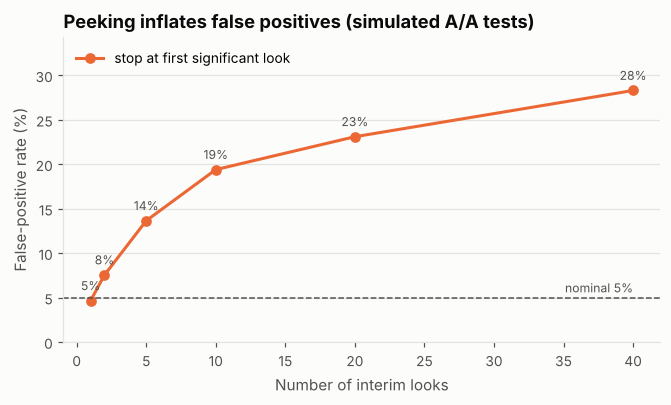

,fixed_horizon_fpr,peeking_fpr,n_looks,n_sims
0,0.0465,0.0465,1,2000
1,0.0465,0.0755,2,2000
2,0.0455,0.1365,5,2000
3,0.0490,0.1940,10,2000
4,0.0475,0.2310,20,2000
5,0.0535,0.2830,40,2000


In [12]:
looks = [1, 2, 5, 10, 20, 40]
peek = pd.DataFrame([peeking_false_positive_rate(p0, n_total // 2, k, n_sims=2000, seed=RANDOM_SEED) for k in looks])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(peek.n_looks, peek.peeking_fpr * 100, marker="o", color=SERIES[1], label="stop at first significant look")
ax.axhline(5, color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.text(looks[-1], 5.6, "nominal 5%", ha="right", fontsize=8, color=INK_SECONDARY)
for k, v in zip(peek.n_looks, peek.peeking_fpr):
    ax.text(k, v * 100 + 1.2, f"{v:.0%}", ha="center", fontsize=8, color=INK_SECONDARY)
ax.set_xlabel("Number of interim looks")
ax.set_ylabel("False-positive rate (%)")
ax.set_ylim(0, peek.peeking_fpr.max() * 100 + 6)
ax.set_title("Peeking inflates false positives (simulated A/A tests)")
ax.legend(loc="upper left")
save(fig, "ab_peeking")
plt.show()
results["ab_peeking"] = peek.to_dict(orient="records")
peek

### 7. Novelty effect (simulated)

Customers may react to a new "free shipping" banner more strongly at first than in steady state. Below, the true lift starts at 30% and decays to a steady 10% (time constant 10 days). We replicate the experiment 500 times at real traffic. The line is the average measured cumulative lift and the band is the 10th–90th percentile.

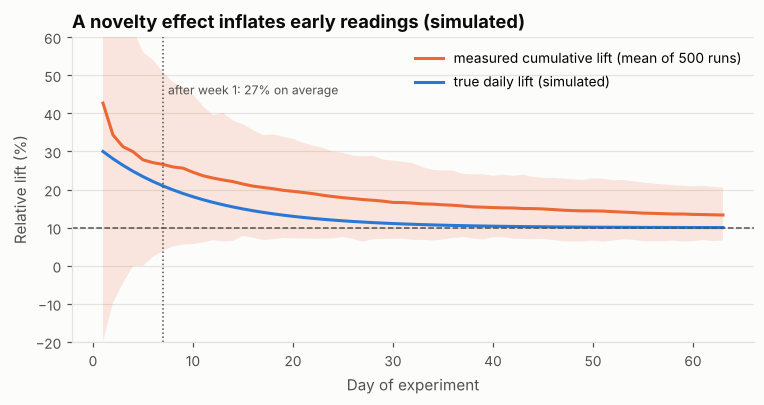

Mean measured lift after 7 days: 26.6% (80% band 4% to 51%); after 63 days: 13.3%; steady-state truth: 10%


In [13]:
days_n = weeks * 7
t = np.arange(days_n)
true_daily = 0.10 + 0.20 * np.exp(-t / 10)
rng2 = np.random.default_rng(RANDOM_SEED)
per_arm_day = int(daily_orders / 2)
xa = rng2.binomial(per_arm_day, p0, (500, days_n))
xb = rng2.binomial(per_arm_day, p0 * (1 + true_daily), (500, days_n))
cum = np.cumsum(xb, axis=1) / np.cumsum(xa, axis=1) - 1
mean_cum, lo, hi = cum.mean(axis=0), np.quantile(cum, 0.1, axis=0), np.quantile(cum, 0.9, axis=0)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.fill_between(t + 1, lo * 100, hi * 100, color=SERIES[1], alpha=0.15, linewidth=0)
ax.plot(t + 1, mean_cum * 100, color=SERIES[1], label="measured cumulative lift (mean of 500 runs)")
ax.plot(t + 1, true_daily * 100, color=SERIES[0], label="true daily lift (simulated)")
ax.axhline(10, color=INK_SECONDARY, linestyle="--", linewidth=1)
ax.axvline(7, color=INK_SECONDARY, linestyle=":", linewidth=1)
ax.text(7.5, 45, f"after week 1: {mean_cum[6]:.0%} on average", fontsize=8, color=INK_SECONDARY)
ax.set_xlabel("Day of experiment")
ax.set_ylabel("Relative lift (%)")
ax.set_ylim(-20, 60)
ax.set_title("A novelty effect inflates early readings (simulated)")
ax.legend(loc="upper right")
save(fig, "ab_novelty")
plt.show()
print(f"Mean measured lift after 7 days: {mean_cum[6]:.1%} (80% band {lo[6]:.0%} to {hi[6]:.0%}); after {days_n} days: {mean_cum[-1]:.1%}; steady-state truth: 10%")
results["ab_novelty"] = {"week1_mean": float(mean_cum[6]), "end_mean": float(mean_cum[-1]), "steady_state": 0.10}

**So what (Part B, ⚠️ simulated outcomes, real calibration).**
- **Design is the binding constraint.** At Olist's real 2018 volume (**222 orders/day**, baseline multi-item rate **9.90%**), detecting a 10% relative lift needs **135 days**. We planned for a 15% MDE: **6,763 per arm**, rounded up to **9 full weeks** (13,993 orders), 81% power.
- **SRM check passed** (p = 0.74). A buggy 52/48 split of the same traffic would be flagged (p = 2×10⁻⁶), so the test runs before anyone looks at the metric.
- **Primary metric:** 10.01% → 11.44%, **+1.43 pp** (95% CI +0.41 to +2.46 pp), p = 0.006. Bayesian view: **P(B > A) = 99.7%**, expected loss of shipping B ≈ 0.001 pp, and a 95% credible interval for the lift of +3.8% to +25.8%.
- **The guardrails say do not ship as designed.** Review score (−0.01, p = 0.65) and AOV (p = 0.72) do not move detectably. However, the freight subsidy costs **R\$ 9.60 per order** while the extra multi-item orders add only about **R\$ 1.44 of GMV per order**, because **26%** of orders already clear the R\$ 150 threshold and get free shipping for doing nothing new. The next iteration should test a threshold **just above typical single-item baskets** or a **partial subsidy**, and it needs margin data to judge profit instead of GMV.
- **Process rules:** checking 20 times and stopping at the first p < 0.05 turns a 5% false-positive rate into **23%** (28% with 40 looks). Use a fixed horizon or a proper sequential test. A novelty effect can make week-1 readings **2.7x** the steady-state lift (26.6% vs a true 10%), so run whole weeks, report lift by week of exposure and keep a long-term holdout.

In [14]:
METRICS_DIR.mkdir(parents=True, exist_ok=True)
(METRICS_DIR / "stats.json").write_text(json.dumps(results, indent=2, default=float))
con.close()
print("saved", METRICS_DIR / "stats.json")

saved /home/user/olist-ecommerce-analytics/results/metrics/stats.json
